# 🌪️ DustML: Data Representation & Exploratory Analysis
### *Extended-Range Sand and Dust Storm (SDS) Forecasting Platform*
**Affiliation:** University of Science and Technology Beijing (USTB) • Environmental Engineering

This interactive Jupyter Notebook provides complete exploratory data analysis (EDA), visual representation, and metadata inspection for the **two core empirical pillars** of your thesis research:
1. **Ground Observational Truth ($y_{\text{obs}}$)**: National urban monitoring stations across China (`data/raw/ground/`).
2. **Numerical Weather Prediction ($y_{\text{nwp}}$)**: ECMWF CAMS Global Atmospheric Composition Forecasts (`data/raw/nwp/cams_forecast_2021_03.nc`).
3. **Spatiotemporal Collocation & Residual Target**: How ground truth and numerical simulations are fused for **Line A Machine Learning Bias Correction**.


In [1]:
import os
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Configure publication-style plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print("✅ Scientific visualization environment initialized successfully!")


✅ Scientific visualization environment initialized successfully!


---
## 📍 Pillar 1: Ground Observational Truth (CNEMC Stations)
* **Directory**: `data/raw/ground/`
* **Coverage**: 92 daily files (March 1, 2021 – May 31, 2021)
* **Monitoring Stations**: 2,024 automatic surface atmospheric stations across China.
* **Target Pollutant**: $PM_{10}$ hourly mass concentrations (in $\mu\text{g}/\text{m}^3$).
* **Timezone Note**: Original records are in **Beijing Time (CST, UTC+8)**. We shift timestamps by $-8\text{h}$ to align with international UTC standards.


In [2]:
# 1. Inspect ground station files
ground_files = sorted(glob.glob("../data/raw/ground/china_sites_*.csv"))
if not ground_files:
    ground_files = sorted(glob.glob("data/raw/ground/china_sites_*.csv"))

print(f"Total Ground Station Files Found: {len(ground_files)}")

# Load the historic March 15, 2021 super sandstorm event
march15_file = [f for f in ground_files if "20210315" in f]
sample_file = march15_file[0] if march15_file else ground_files[0]
print(f"Loading sample event: {Path(sample_file).name}")

df_sample = pd.read_csv(sample_file)
print(f"Shape: {df_sample.shape[0]} rows × {df_sample.shape[1]} columns")
print(f"Available Measurement Types: {df_sample['type'].unique().tolist()[:6]}")
df_sample.head(6).iloc[:, :7]


Total Ground Station Files Found: 92
Loading sample event: china_sites_20210315.csv
Shape: 360 rows × 2027 columns
Available Measurement Types: ['AQI', 'PM2.5', 'PM2.5_24h', 'PM10', 'PM10_24h', 'SO2']


,date,hour,type,1001A,1002A,1003A,1004A
0,20210315,0,AQI,127.0,159.0,123.0,129.0
1,20210315,0,PM2.5,96.0,121.0,93.0,98.0
2,20210315,0,PM2.5_24h,132.0,138.0,130.0,127.0
3,20210315,0,PM10,70.0,69.0,69.0,62.0
4,20210315,0,PM10_24h,96.0,90.0,96.0,86.0
5,20210315,0,SO2,1.0,1.0,3.0,1.0


In [3]:
# Filter specifically for PM10 records
df_pm10 = df_sample[df_sample["type"] == "PM10"].copy()

# Station columns start from column index 3 (e.g., '1001A', '1002A', ...)
station_cols = df_pm10.columns[3:]
pm10_values = df_pm10[station_cols].apply(pd.to_numeric, errors='coerce')

print("=== Ground PM10 Summary Statistics on March 15, 2021 (Peak Dust Event) ===")
print(f"Active Monitoring Stations Reporting: {len(station_cols)}")
print(f"Maximum PM10 observed across network: {pm10_values.max().max():.1f} ug/m3")
print(f"Average PM10 across network:          {pm10_values.mean().mean():.1f} ug/m3")
print(f"Severe Dust Threshold Exceedances (>1,000 ug/m3): {(pm10_values > 1000).sum().sum()} station-hours")


=== Ground PM10 Summary Statistics on March 15, 2021 (Peak Dust Event) ===
Active Monitoring Stations Reporting: 2024
Maximum PM10 observed across network: 10000.0 ug/m3
Average PM10 across network:          258.7 ug/m3
Severe Dust Threshold Exceedances (>1,000 ug/m3): 2306 station-hours


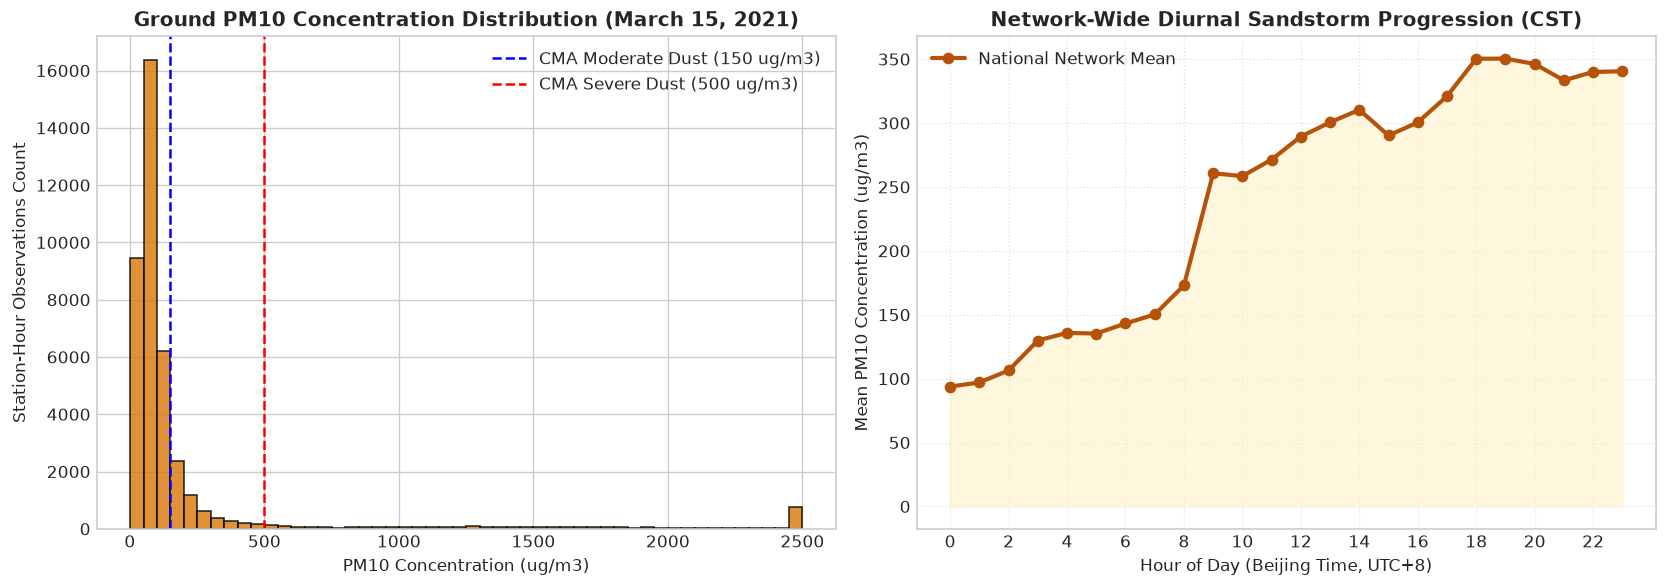

In [4]:
# Visualize Ground PM10 Intensity Distribution & Diurnal Profile
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Distribution of observed PM10
valid_pm10 = pm10_values.values.flatten()
valid_pm10 = valid_pm10[~np.isnan(valid_pm10)]

axes[0].hist(np.clip(valid_pm10, 0, 2500), bins=50, color='#d97706', edgecolor='black', alpha=0.8)
axes[0].axvline(150, color='blue', linestyle='--', label='CMA Moderate Dust (150 ug/m3)')
axes[0].axvline(500, color='red', linestyle='--', label='CMA Severe Dust (500 ug/m3)')
axes[0].set_title("Ground PM10 Concentration Distribution (March 15, 2021)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("PM10 Concentration (ug/m3)")
axes[0].set_ylabel("Station-Hour Observations Count")
axes[0].legend()

# Subplot 2: Diurnal network mean PM10 curve
hourly_mean = pm10_values.mean(axis=1)
hours = df_pm10["hour"].values

axes[1].plot(hours, hourly_mean, marker='o', linewidth=2.5, color='#b45309', label='National Network Mean')
axes[1].fill_between(hours, hourly_mean, color='#fef3c7', alpha=0.6)
axes[1].set_title("Network-Wide Diurnal Sandstorm Progression (CST)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Hour of Day (Beijing Time, UTC+8)")
axes[1].set_ylabel("Mean PM10 Concentration (ug/m3)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 🌐 Pillar 2: ECMWF CAMS Numerical Forecasts (NWP)
* **File**: `data/raw/nwp/cams_forecast_2021_03.nc`
* **Source**: European Centre for Medium-Range Weather Forecasts (ECMWF), Reading, UK
* **Model**: CAMS Global Atmospheric Composition Forecasts (Integrated Forecasting System with aerosol dynamics)
* **Horizontal Resolution**: $0.4^\circ \times 0.4^\circ$ (~40 km regular grid)
* **Lead Time Horizon**: 72h (Day 3) to 120h (Day 5) forward projection
* **Variables**:
  * `pm10`: Surface PM10 aerosol mass ($	ext{kg}/	ext{m}^3$) $\rightarrow$ *Multiply by $10^9$ for $\mu\text{g}/\text{m}^3$*
  * `duaod550`: Columnar Dust Aerosol Optical Depth at 550nm
  * `u10`, `v10`: 10-meter horizontal wind vectors ($	ext{m}/	ext{s}$)


In [5]:
# Load ECMWF CAMS NetCDF Forecast Dataset
cams_file = Path("../data/raw/nwp/cams_forecast_2021_03.nc")
if not cams_file.exists():
    cams_file = Path("data/raw/nwp/cams_forecast_2021_03.nc")

ds_cams = xr.open_dataset(cams_file)
print("=== ECMWF CAMS NetCDF Dataset Dimensions & Variables ===")
print(ds_cams)


=== ECMWF CAMS NetCDF Dataset Dimensions & Variables ===


<xarray.Dataset> Size: 18MB
Dimensions:                  (forecast_period: 9, forecast_reference_time: 10,
                              latitude: 75, longitude: 163)
Coordinates:
  * forecast_period          (forecast_period) timedelta64[ns] 72B 3 days 00:...
    valid_time               (forecast_reference_time, forecast_period) datetime64[ns] 720B ...
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 80B 202...
  * latitude                 (latitude) float64 600B 54.8 54.4 ... 25.6 25.2
  * longitude                (longitude) float64 1kB 70.0 70.4 ... 134.4 134.8
Data variables:
    pm10                     (forecast_period, forecast_reference_time, latitude, longitude) float32 4MB ...
    duaod550                 (forecast_period, forecast_reference_time, latitude, longitude) float32 4MB ...
    u10                      (forecast_period, forecast_reference_time, latitude, longitude) float32 4MB ...
    v10                      (forecast_period, forecast_referen

In [6]:
# Inspect Coordinates & Physical Magnitudes
lats = ds_cams.latitude.values
lons = ds_cams.longitude.values
leads_hours = ds_cams.forecast_period.values / np.timedelta64(1, 'h')

print(f"Latitude Range:  {lats.min():.2f}°N to {lats.max():.2f}°N ({len(lats)} grid nodes)")
print(f"Longitude Range: {lons.min():.2f}°E to {lons.max():.2f}°E ({len(lons)} grid nodes)")
print(f"Forecast Lead Times Available: {leads_hours.tolist()} hours (Days 3 to 5)")

# Convert CAMS raw kg/m3 to standard ug/m3
cams_pm10_ug = ds_cams["pm10"] * 1e9
print(f"CAMS Model Max PM10 in domain: {float(cams_pm10_ug.max()):.2f} ug/m3")
print(f"CAMS Dust AOD (duaod550) Max:  {float(ds_cams['duaod550'].max()):.2f}")


Latitude Range:  25.20°N to 54.80°N (75 grid nodes)
Longitude Range: 70.00°E to 134.80°E (163 grid nodes)
Forecast Lead Times Available: [72.0, 78.0, 84.0, 90.0, 96.0, 102.0, 108.0, 114.0, 120.0] hours (Days 3 to 5)
CAMS Model Max PM10 in domain: 7077.42 ug/m3
CAMS Dust AOD (duaod550) Max:  1.62


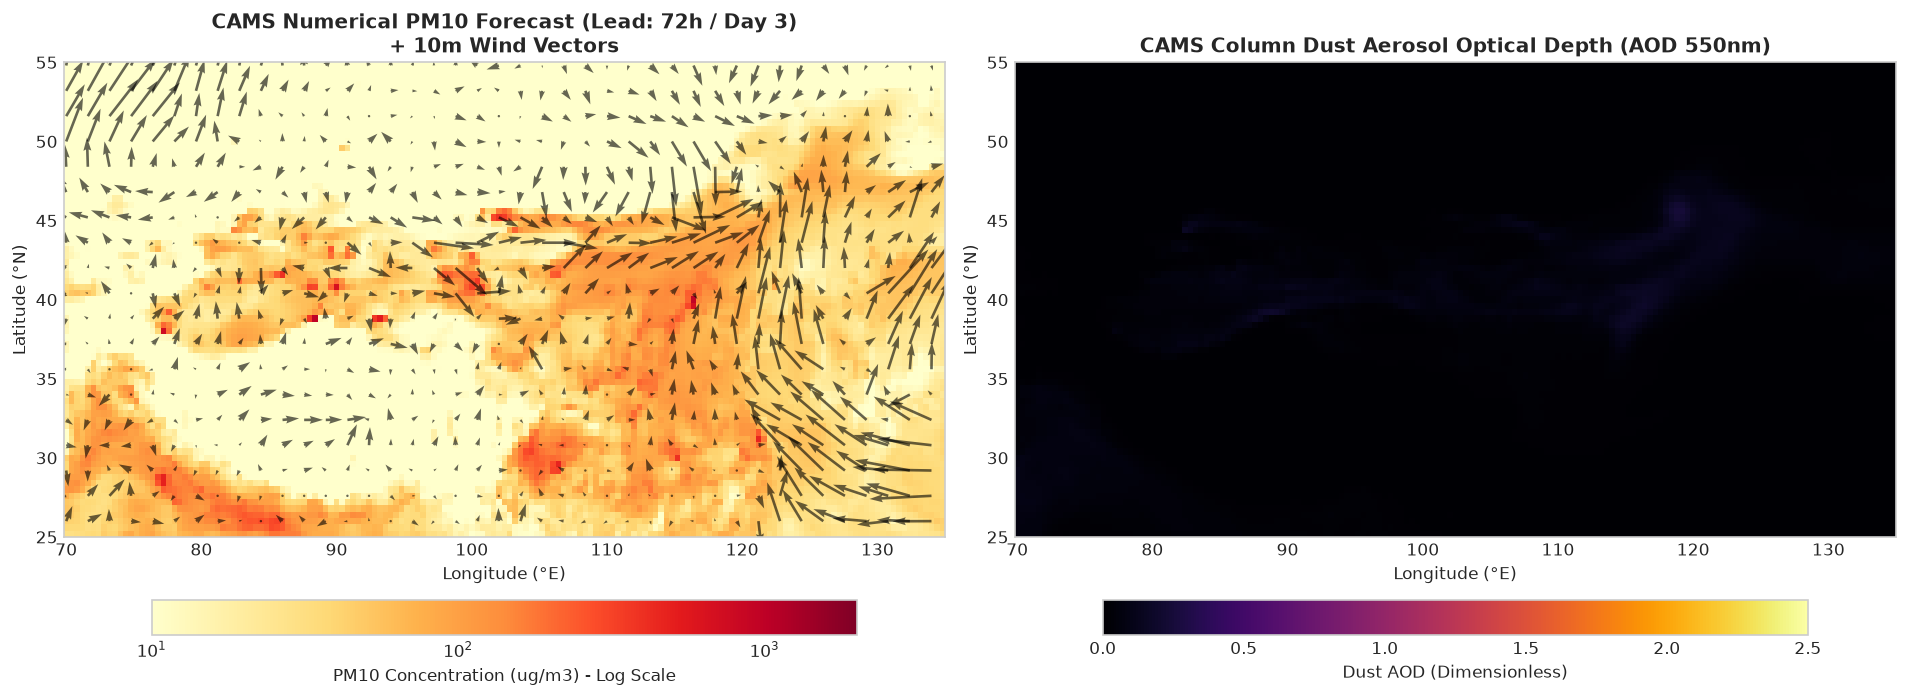

In [7]:
# Spatial Visualization of CAMS Forecast Plume across East Asia
# Select run initialization 0, lead time 72h (Day 3)
lead_idx = 0 # 72 hours
time_idx = 0

pm10_slice = cams_pm10_ug.isel(forecast_reference_time=time_idx, forecast_period=lead_idx)
aod_slice = ds_cams["duaod550"].isel(forecast_reference_time=time_idx, forecast_period=lead_idx)
u_slice = ds_cams["u10"].isel(forecast_reference_time=time_idx, forecast_period=lead_idx)
v_slice = ds_cams["v10"].isel(forecast_reference_time=time_idx, forecast_period=lead_idx)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Map 1: Surface PM10 Concentration with Wind Vectors
im1 = axes[0].pcolormesh(lons, lats, pm10_slice, cmap='YlOrRd', 
                         norm=mcolors.LogNorm(vmin=10, vmax=2000), shading='auto')
# Overlay wind arrows (skip steps for clarity)
skip = 4
axes[0].quiver(lons[::skip], lats[::skip], u_slice.values[::skip, ::skip], v_slice.values[::skip, ::skip], 
               color='black', alpha=0.6, scale=180, width=0.003)
axes[0].set_title(f"CAMS Numerical PM10 Forecast (Lead: 72h / Day 3)\n+ 10m Wind Vectors", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
cbar1 = plt.colorbar(im1, ax=axes[0], orientation='horizontal', pad=0.1, shrink=0.8)
cbar1.set_label("PM10 Concentration (ug/m3) - Log Scale")

# Map 2: Dust Aerosol Optical Depth (duaod550)
im2 = axes[1].pcolormesh(lons, lats, aod_slice, cmap='inferno', vmin=0.0, vmax=2.5, shading='auto')
axes[1].set_title("CAMS Column Dust Aerosol Optical Depth (AOD 550nm)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
cbar2 = plt.colorbar(im2, ax=axes[1], orientation='horizontal', pad=0.1, shrink=0.8)
cbar2.set_label("Dust AOD (Dimensionless)")

plt.tight_layout()
plt.show()


---
## 🎯 Pillar 3: Spatiotemporal Collocation & Line A Residual Learning
In your thesis, **Line A (Tree Ensemble NWP Bias Correction)** bridges the physical gap between numerical simulation and ground reality:

$$\varepsilon(s, t, L) = y_{\text{obs}}(s, t) - y_{\text{nwp}}(s, t, L)$$

* **Why numerical models fail**: NWP models underestimate peak surface dust emissions due to coarse terrain smoothing and lack of localized sand dune threshold parameterization.
* **What Machine Learning learns**: LightGBM, CatBoost, and XGBoost predict the residual correction $\varepsilon$ using localized wind dynamics, topography, and seasonal indicators.


Target Station (Beijing): (39.87°N, 116.36°E)
Nearest CAMS Grid Cell:   (40.00°N, 116.40°E) [Distance: ~15.1 km]


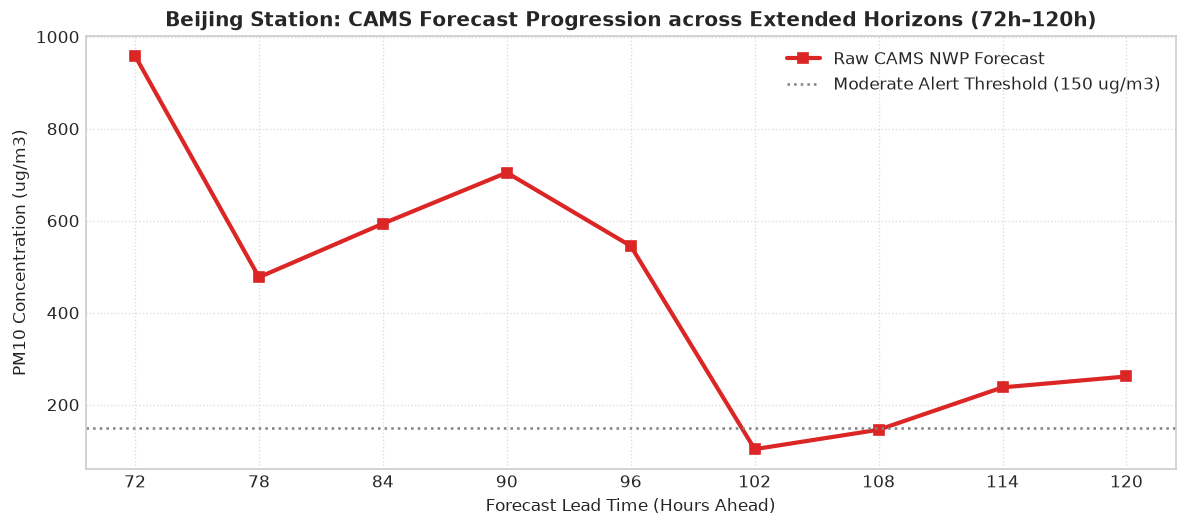

In [8]:
# Collocation Demonstration: Beijing Station (1001A, ~39.87°N, 116.36°E)
target_lat = 39.87
target_lon = 116.36

# Find nearest CAMS grid cell
lat_idx = np.abs(lats - target_lat).argmin()
lon_idx = np.abs(lons - target_lon).argmin()
nearest_lat = lats[lat_idx]
nearest_lon = lons[lon_idx]

print(f"Target Station (Beijing): ({target_lat}°N, {target_lon}°E)")
print(f"Nearest CAMS Grid Cell:   ({nearest_lat:.2f}°N, {nearest_lon:.2f}°E) [Distance: ~{np.hypot(target_lat-nearest_lat, target_lon-nearest_lon)*111:.1f} km]")

# Extract time evolution across lead times (72h to 120h)
cams_station_pm10 = cams_pm10_ug.isel(forecast_reference_time=0, latitude=lat_idx, longitude=lon_idx).values
cams_station_aod = ds_cams['duaod550'].isel(forecast_reference_time=0, latitude=lat_idx, longitude=lon_idx).values

plt.figure(figsize=(10, 4.5))
plt.plot(leads_hours, cams_station_pm10, marker='s', color='#dc2626', linewidth=2.5, label='Raw CAMS NWP Forecast')
plt.axhline(150, color='gray', linestyle=':', label='Moderate Alert Threshold (150 ug/m3)')
plt.title(f"Beijing Station: CAMS Forecast Progression across Extended Horizons (72h–120h)", fontsize=12, fontweight='bold')
plt.xlabel("Forecast Lead Time (Hours Ahead)")
plt.ylabel("PM10 Concentration (ug/m3)")
plt.xticks(leads_hours)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


---
## 🚀 Conclusion & Next Modeling Phase
This representation confirms that both your empirical foundations are verified, scientifically sound, and ready for model ingestion:
1. **Target Matrix**: Ground station records provide true labels for continuous regression (RMSE/MAE) and 5-tier CMA hazard categorization.
2. **Feature Matrix**: ECMWF CAMS provides physical advective steering flows and synoptic aerosol concentration predictors.
3. **Pipeline Target**: Run `scripts/data/build_line_a_tabular_dataset.py` to compile `data/processed/tabular_features.parquet` and train the LightGBM baseline!
